In [17]:
import pandas as pd
import numpy as np
from pmdarima import auto_arima

In [18]:
"""import sys
!"{sys.executable}" -m pip install pmdarima """

'import sys\n!"{sys.executable}" -m pip install pmdarima '

In [19]:
Kandi=pd.read_csv("data\Kandi_final.csv")
Parakou=pd.read_csv("data\Parakou_final.csv")

<>:1: SyntaxWarning: invalid escape sequence '\K'
<>:2: SyntaxWarning: invalid escape sequence '\P'
<>:1: SyntaxWarning: invalid escape sequence '\K'
<>:2: SyntaxWarning: invalid escape sequence '\P'
C:\Users\HP CORE I5\AppData\Local\Temp\ipykernel_8260\3890621831.py:1: SyntaxWarning: invalid escape sequence '\K'
  Kandi=pd.read_csv("data\Kandi_final.csv")
C:\Users\HP CORE I5\AppData\Local\Temp\ipykernel_8260\3890621831.py:2: SyntaxWarning: invalid escape sequence '\P'
  Parakou=pd.read_csv("data\Parakou_final.csv")


In [20]:
Kandi["Pluviometrie"]

0       0.0
1       0.0
2       0.0
3       0.0
4       0.0
       ... 
4012    0.0
4013    0.0
4014    0.0
4015    0.0
4016    0.0
Name: Pluviometrie, Length: 4017, dtype: float64

In [21]:
def changement(x):
    if x<10:
        return f"0{x}"
    else :
        return f"{x}"
Kandi["Date"]=Kandi["annee"].apply(changement)+"-"+Kandi["mois"].apply(changement)+"-"+Kandi["jour"].apply(changement)
Kandi["Date"]=pd.to_datetime(Kandi["Date"])
Kandi=Kandi.set_index("Date")


Parakou["Date"]=Parakou["annee"].apply(changement)+"-"+Parakou["mois"].apply(changement)+"-"+Parakou["jour"].apply(changement)
Parakou["Date"]=pd.to_datetime(Parakou.Date)
Parakou=Parakou.set_index("Date")

In [22]:
Kandi.head()

,Lieu,annee,mois,jour,Pression,Temperature_Max,Temperature_Min,Humidite,Vitesse_Vent,Pluviometrie
Date,,,,,,,,,,
2015-01-01,KANDI_AEROPORT,2015,1,1,979.9,32.0,13.4,32.0,2.4,0.0
2015-01-02,KANDI_AEROPORT,2015,1,2,981.4,30.3,17.4,26.0,2.3,0.0
2015-01-03,KANDI_AEROPORT,2015,1,3,982.8,29.2,17.7,20.0,3.5,0.0
2015-01-04,KANDI_AEROPORT,2015,1,4,983.8,29.0,15.8,20.0,2.8,0.0
2015-01-05,KANDI_AEROPORT,2015,1,5,982.7,29.5,13.5,29.0,3.0,0.0


In [23]:
Kandi_pluie_train=Kandi[Kandi.annee<2024]["Pluviometrie"]
Kandi_pluie_test=Kandi[2024<=Kandi.annee]["Pluviometrie"]

Parakou_pluie_train=Parakou[Parakou.annee<2024]["Pluviometrie"]
Parakou_pluie_test=Parakou[2024<=Parakou.annee]["Pluviometrie"]

Kandi_pluie_train

Date
2015-01-01    0.0
2015-01-02    0.0
2015-01-03    0.0
2015-01-04    0.0
2015-01-05    0.0
             ... 
2023-12-27    0.0
2023-12-28    0.0
2023-12-29    0.0
2023-12-30    0.0
2023-12-31    0.0
Name: Pluviometrie, Length: 3286, dtype: float64

In [24]:
from sklearn.metrics import mean_absolute_error,mean_squared_error
def calcul_erreur_auto(train,test):
    model=auto_arima(train,seasonal=False,trace=True,start_p=1,start_q=1,max_p=10,max_q=10,d=0)
    prediction=model.predict(n_periods=len(test))
    return {"Resultats":model,"MAE":mean_absolute_error(test,prediction),"RMSE":np.sqrt(mean_squared_error(test,prediction))}
    


In [25]:
import matplotlib.pyplot as plt
def calcul_erreur_final(train,test,p,q):
    model=auto_arima(train,seasonal=False,trace=True,start_p=p,start_q=q,max_p=p,max_q=q,d=0)
    prediction=model.predict(n_periods=len(test))
    plt.figure(figsize=(10,5))
    plt.plot(test.index,test,label="Test")
    plt.plot(test.index,prediction,label="Prediction")
    plt.legend()
    return {"Resultats":model,"MAE":mean_absolute_error(test,prediction),"RMSE":np.sqrt(mean_squared_error(test,prediction))}

In [26]:
"""Calcul_Kandi=calcul_erreur_auto(Kandi_pluie_train,Kandi_pluie_test)

Calcul_Parakou=calcul_erreur_auto(Parakou_pluie_train,Parakou_pluie_test)"""

'Calcul_Kandi=calcul_erreur_auto(Kandi_pluie_train,Kandi_pluie_test)\n\nCalcul_Parakou=calcul_erreur_auto(Parakou_pluie_train,Parakou_pluie_test)'

In [27]:
#Calcul_Kandi

In [28]:
#Calcul_Kandi["Resultats"].order

In [29]:
"""resultats=pd.concat([pd.DataFrame({"Station":["Kandi"],"p":Calcul_Kandi["Resultats"].order[0],"q":Calcul_Kandi["Resultats"].order[-1],"MAE":Calcul_Kandi["MAE"],"RMSE":Calcul_Kandi["RMSE"]}),
                    pd.DataFrame({"Station":["Parakou"],"p":Calcul_Parakou["Resultats"].order[0],"q":Calcul_Parakou["Resultats"].order[-1],"MAE":Calcul_Parakou["MAE"],"RMSE":Calcul_Parakou["RMSE"]})],axis=0)


resultats"""

'resultats=pd.concat([pd.DataFrame({"Station":["Kandi"],"p":Calcul_Kandi["Resultats"].order[0],"q":Calcul_Kandi["Resultats"].order[-1],"MAE":Calcul_Kandi["MAE"],"RMSE":Calcul_Kandi["RMSE"]}),\n                    pd.DataFrame({"Station":["Parakou"],"p":Calcul_Parakou["Resultats"].order[0],"q":Calcul_Parakou["Resultats"].order[-1],"MAE":Calcul_Parakou["MAE"],"RMSE":Calcul_Parakou["RMSE"]})],axis=0)\n\n\nresultats'

In [30]:
#resultats.to_csv("data/resultats_arima.csv",index=False)

Performing stepwise search to minimize aic
 ARIMA(6,0,2)(0,0,0)[0]             : AIC=23852.995, Time=4.35 sec
 ARIMA(0,0,0)(0,0,0)[0]             : AIC=24534.040, Time=0.05 sec
 ARIMA(1,0,0)(0,0,0)[0]             : AIC=24410.670, Time=0.08 sec
 ARIMA(0,0,1)(0,0,0)[0]             : AIC=24440.264, Time=0.24 sec
 ARIMA(5,0,2)(0,0,0)[0]             : AIC=23865.272, Time=3.30 sec
 ARIMA(6,0,1)(0,0,0)[0]             : AIC=23854.300, Time=2.18 sec
 ARIMA(5,0,1)(0,0,0)[0]             : AIC=23857.974, Time=2.08 sec
 ARIMA(6,0,2)(0,0,0)[0] intercept   : AIC=23845.118, Time=8.26 sec
 ARIMA(5,0,2)(0,0,0)[0] intercept   : AIC=23858.196, Time=8.96 sec
 ARIMA(6,0,1)(0,0,0)[0] intercept   : AIC=23846.096, Time=7.84 sec
 ARIMA(5,0,1)(0,0,0)[0] intercept   : AIC=23850.440, Time=6.12 sec

Best model:  ARIMA(6,0,2)(0,0,0)[0] intercept
Total fit time: 43.481 seconds


d:\LATEX\Stage\VSCODE Python\venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
d:\LATEX\Stage\VSCODE Python\venv\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(


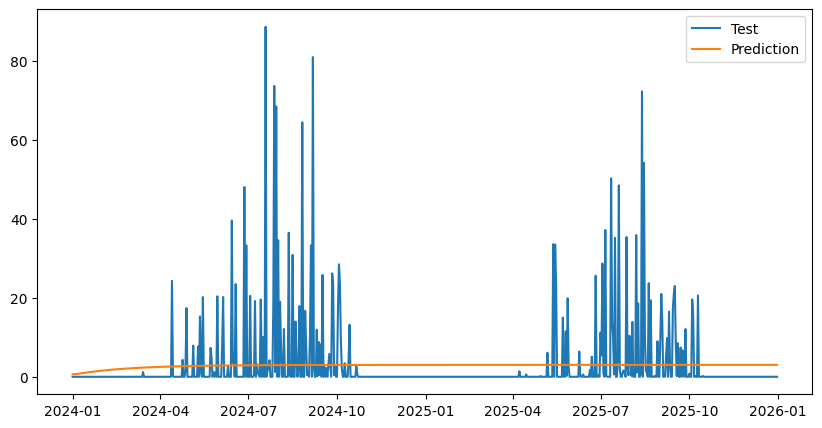

In [31]:
Calcul_KandiF=calcul_erreur_final(Kandi_pluie_train,Kandi_pluie_test,6,2)

Performing stepwise search to minimize aic
 ARIMA(3,0,1)(0,0,0)[0]             : AIC=24218.933, Time=1.29 sec
 ARIMA(0,0,0)(0,0,0)[0]             : AIC=24776.765, Time=0.05 sec
 ARIMA(1,0,0)(0,0,0)[0]             : AIC=24707.905, Time=0.10 sec
 ARIMA(0,0,1)(0,0,0)[0]             : AIC=24723.676, Time=0.31 sec
 ARIMA(2,0,1)(0,0,0)[0]             : AIC=24221.833, Time=1.10 sec
 ARIMA(3,0,0)(0,0,0)[0]             : AIC=24535.802, Time=0.64 sec
 ARIMA(2,0,0)(0,0,0)[0]             : AIC=24631.763, Time=0.14 sec
 ARIMA(3,0,1)(0,0,0)[0] intercept   : AIC=24208.857, Time=3.33 sec
 ARIMA(2,0,1)(0,0,0)[0] intercept   : AIC=24212.359, Time=2.01 sec
 ARIMA(3,0,0)(0,0,0)[0] intercept   : AIC=24373.086, Time=0.70 sec
 ARIMA(2,0,0)(0,0,0)[0] intercept   : AIC=24414.132, Time=0.29 sec

Best model:  ARIMA(3,0,1)(0,0,0)[0] intercept
Total fit time: 9.972 seconds


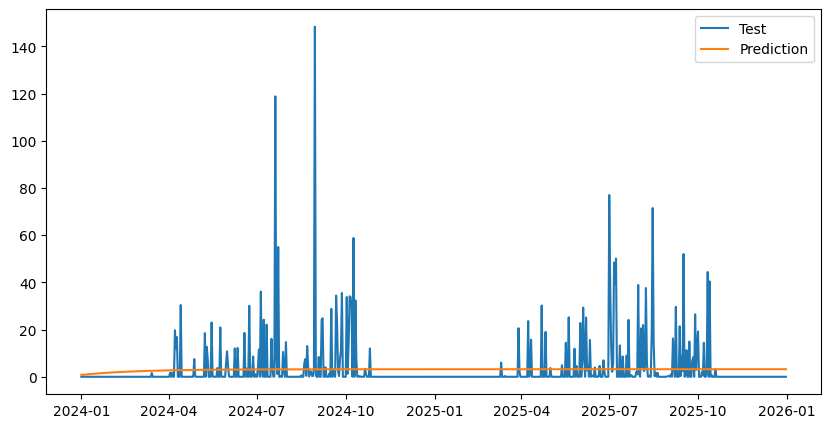

In [32]:
Calcul_ParakouF=calcul_erreur_final(Parakou_pluie_train,Parakou_pluie_test,3,1)

In [33]:
resultats_final=pd.concat([pd.DataFrame({"Station":["Kandi"],"p":Calcul_KandiF["Resultats"].order[0],"q":Calcul_KandiF["Resultats"].order[-1],"MAE":Calcul_KandiF["MAE"],"RMSE":Calcul_KandiF["RMSE"]}),
                    pd.DataFrame({"Station":["Parakou"],"p":Calcul_ParakouF["Resultats"].order[0],"q":Calcul_ParakouF["Resultats"].order[-1],"MAE":Calcul_ParakouF["MAE"],"RMSE":Calcul_ParakouF["RMSE"]})],axis=0)


resultats_final

,Station,p,q,MAE,RMSE
0,Kandi,6,2,4.890643,9.851040
0,Parakou,3,1,5.270873,11.345777
